# Rendering visual stimuli

In [ ]:
import io
import re

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image as ShowImage
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from PIL import Image
from scipy import interpolate

In [13]:
obj_id = 219


# complete your path
path = (f"...../multimodal_analysis/visual_stimuli/{obj_id}.egg")

238065 vertices, 79355 polygons


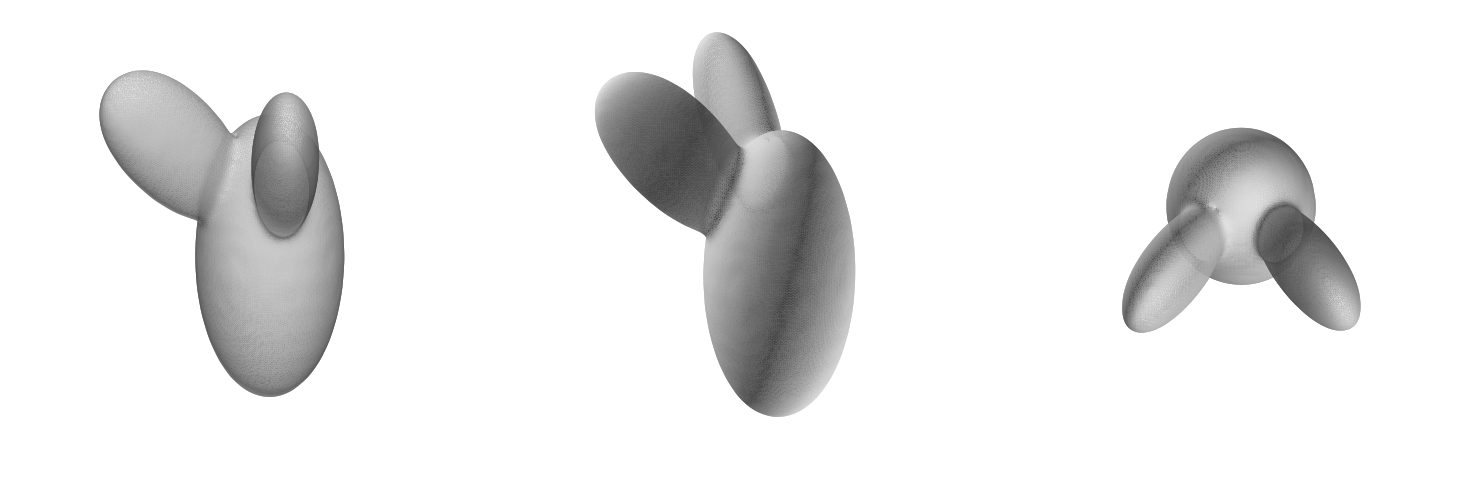

In [14]:
MAX_FACES = 100_000  # matplotlib gets slow above this; extra faces are subsampled
MAX_POINTS = 40_000  # points drawn if the file has no faces

text = open(path).read()

# ---------- read vertices ----------
num = r"[-+]?(?:\d+\.?\d*|\.\d+)(?:[eE][-+]?\d+)?"
pools, cur = {}, None
vpat = re.compile(
    r'<VertexPool>\s+"?([^\s"{]+)"?|<Vertex>\s+(\d+)\s*\{\s*(%s)\s+(%s)\s+(%s)'
    % (num, num, num),
    re.I,
)
for m in vpat.finditer(text):
    if m.group(1):
        cur = m.group(1)
        pools.setdefault(cur, {})
    else:
        pools[cur][int(m.group(2))] = (
            float(m.group(3)),
            float(m.group(4)),
            float(m.group(5)),
        )

# ---------- read polygons ----------
fpat = re.compile(r'<VertexRef>\s*\{([^<]*)<Ref>\s*\{\s*"?([^\s"}]+)"?\s*\}', re.I)
faces = []
for m in fpat.finditer(text):
    pool = pools.get(m.group(2), {})
    idx = [int(i) for i in m.group(1).split()]
    if len(idx) >= 3 and all(i in pool for i in idx):
        faces.append(np.array([pool[i] for i in idx]))

V = np.array([v for p in pools.values() for v in p.values()])
print(f"{len(V)} vertices, {len(faces)} polygons")

lo, hi = V.min(0), V.max(0)
span = np.where(hi - lo > 0, hi - lo, 1)
rng = np.random.default_rng(0)

# ---------- prepare surface or point cloud ----------
if faces:
    if len(faces) > MAX_FACES:
        faces = [faces[i] for i in rng.choice(len(faces), MAX_FACES, replace=False)]
    light = np.array([0.4, -0.6, 0.7])
    light /= np.linalg.norm(light)
    shade = []
    for f in faces:
        n = np.cross(f[1] - f[0], f[2] - f[0])
        n /= np.linalg.norm(n) + 1e-12
        shade.append(0.25 + 0.75 * abs(n @ light))
    colors = plt.cm.Greys_r(np.array(shade) * 0.8)
else:
    print("No polygons found - showing the vertices as a point cloud.")
    P = V[rng.choice(len(V), min(MAX_POINTS, len(V)), replace=False)]

# ---------- draw 3 views ----------
fig = plt.figure(figsize=(15, 5))
for k, (elev, azim) in enumerate([(20, -60), (20, 30), (80, -90)]):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    if faces:
        ax.add_collection3d(
            Poly3DCollection(faces, facecolors=colors, edgecolors="none")
        )
    else:
        ax.scatter(P[:, 0], P[:, 1], P[:, 2], s=0.3, c=P[:, 2], cmap="viridis")
    ax.set_xlim(lo[0], hi[0])
    ax.set_ylim(lo[1], hi[1])
    ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect(span)
    ax.view_init(elev, azim)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

79355 triangles, 3570975 sample points


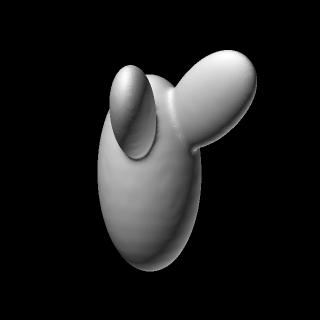

In [20]:

# ---------- your rotation trajectory ----------
interp = (
    lambda x: interpolate.splev(
        np.linspace(0, len(x), 100),
        interpolate.splrep(np.linspace(0, len(x), len(x)), x),
    )
    if len(x) > 3
    else x
)
rot_f = lambda: interp((np.random.rand(20) - 0.5) * 100)
rots = rot_f()

# ---------- settings ----------
SIZE = 320  # gif width/height in pixels
SS = 2  # anti-aliasing (1 = faster, 2 = smoother edges)
ELEV = 20  # camera looks slightly from above (degrees)
FPS = 10

# ---------- prepare geometry (all faces, split into triangles) ----------
tris = np.array(
    [[f[0], f[i], f[i + 1]] for f in faces for i in range(1, len(f) - 1)],
    dtype=np.float32,
)
tris -= (V.min(0) + V.max(0)).astype(np.float32) / 2
scale = (
    np.linalg.norm(tris.reshape(-1, 3), axis=1).max() / 0.95
)  # fits the frame at any rotation
nrm = np.cross(tris[:, 1] - tris[:, 0], tris[:, 2] - tris[:, 0])
nrm /= np.linalg.norm(nrm, axis=1, keepdims=True) + 1e-12

# sample enough points on every triangle so the surface has no gaps
S = SIZE * SS
edge_px = (
    np.linalg.norm(tris - np.roll(tris, 1, axis=1), axis=2).max(1) / (2 * scale) * S
)
n = int(np.clip(np.ceil(np.percentile(edge_px, 99) * 1.5), 1, 8))
B = (
    np.array(
        [(i, j, n - i - j) for i in range(n + 1) for j in range(n + 1 - i)], np.float32
    )
    / n
)
pts = np.einsum("kb,tbd->tkd", B, tris).reshape(-1, 3)
pnr = np.repeat(nrm, len(B), axis=0)
print(f"{len(tris)} triangles, {len(pts)} sample points")

L = np.array([-0.5, -1.0, 0.8], np.float32)
L /= np.linalg.norm(L)  # light from front-left-top


def render(rot_deg, elev_deg=ELEV):
    a, e = np.radians(rot_deg), np.radians(elev_deg)
    Rz = np.array(
        [[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]], np.float32
    )
    Rx = np.array(
        [[1, 0, 0], [0, np.cos(e), -np.sin(e)], [0, np.sin(e), np.cos(e)]], np.float32
    )
    M = Rx @ Rz
    p, nn = pts @ M.T, pnr @ M.T
    px = np.clip(((p[:, 0] / scale + 1) / 2 * S).astype(np.int32), 0, S - 1)
    py = np.clip(((1 - (p[:, 2] / scale + 1) / 2) * S).astype(np.int32), 0, S - 1)
    pix = py * S + px
    o = np.lexsort((p[:, 1], pix))  # per pixel: nearest point first
    ps = pix[o]
    first = np.r_[True, ps[1:] != ps[:-1]]
    img = np.zeros(S * S, np.float32)  # black background
    img[ps[first]] = 0.15 + 0.85 * np.abs(nn[o][first] @ L)  # white, shaded object
    img = img.reshape(SIZE, SS, SIZE, SS).mean((1, 3))
    return (img * 255).astype(np.uint8)


frames = [Image.fromarray(render(r)) for r in rots]
buf = io.BytesIO()
frames[0].save(
    buf,
    format="GIF",
    save_all=True,
    append_images=frames[1:],
    duration=int(1000 / FPS),
    loop=0,
)
ShowImage(data=buf.getvalue(), width=480)  # width just sets the display size